# N-MOSFET

using N-MOSFET set up gate voltage to setup current through MOSFET (see $I_d$ vs $V_{gs}$). The $V_g$ is driven by OpAmp based on $V_s$ through power resistor (shunt) voltage and reference voltage $V_{ref}$.

![](<./falstad/basic_concept.svg>)

## BASIC ASSUMPTIONS
It is impossible? to have one MOSFET going full up to 3.5A and in the same time stay precise in low range of curents.
- modular approach: 4 modules
    - three IXTP4N65X2 MOSFETS for 0.4A to 1A
    - one precise STF2N95K5 for 0 to 0.5A
- maximum total $V_{in}$=24V and $I_{in}$=3.5A
- minimum $V_{in}$=1V and $I_{in}$=0.10mA
- $V_{ref}$ will be set with potentiometer, each mosfet separately
- can be one common display
- interface for current sensing on low side
- device power from external supply: main 220V AC

## THERMAL DISSIPATION

xsd1226-005

![](<./img/xsd1226-005.png>)

In [16]:
displayformat include_comment true
displayformat matrix text
pkg load symbolic
warning('off', 'all');
# THERMAL RESISTANCE
#
# POWER MOSFET
# SPP02N60C3-VB
#
# input
V_in=24 # [V]
I_in=1 #[A]
#
#
# total power to dissipate
P_tot = V_in*I_in #[W]
#

# heat sink XSD1226-039
# estimated, based on `same-sky` datasheet
# at 75degC for aluminum
# 1. natural convection
# 2. at 200LFM
# 3. at 400LFM
K=[1000 400 250]     #[degC * cm^2 / W]
A=94.61 #[cm^2]
Rths= K/A #[degC/W] sink to ambient
#
# TO-220 package
Rthj=1.56 #[degC/W] junction to case
#
# total thermal resistance
Rth =Rthj+Rths
#
# max temp raise above ambient
T = Rth*P_tot #[degC] 

#
# max junction temperature
Tj=150 #[degC]

# THERMAL RESISTANCE

# POWER MOSFET
# SPP02N60C3-VB

# input


V_in = 24 # [V]


I_in = 1 #[A]




# total power to dissipate


P_tot = 24 #[W]



# heat sink XSD1226-039
# estimated, based on `same-sky` datasheet
# at 75degC for aluminum
# 1. natural convection
# 2. at 200LFM
# 3. at 400LFM


... (7 outputs left out)


# max temp raise above ambient


T =    291.11   138.91   100.86 #[degC] 



# max junction temperature


Tj = 150 #[degC]


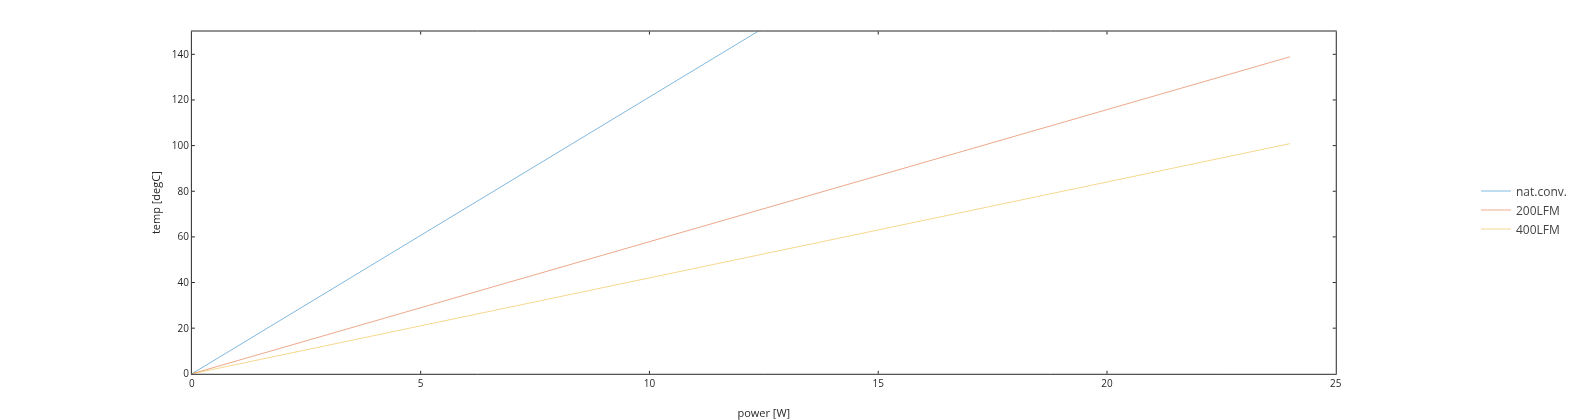

In [17]:
graphics_toolkit plotly
displayformat plotly_interactive_legend true
Px=linspace(0,P_tot);
plot(Px,Px*Rth(1),";nat.conv.;")
hold on
plot(Px,Px*Rth(2),";200LFM;")
plot(Px,Px*Rth(3),";400LFM;")
xlabel("power [W]")
ylabel("temp [degC]")
ylim([0,Tj])

In [18]:
#power on resistor
Rsense=5e-3 #[ohm]
P_r = Rsense * I_in^2 *1e3 #[mW]

#power on resistor


Rsense = 5.0000e-03 #[ohm]


P_r = 5 #[mW]


## CURRENT SENSE

In [19]:
Rsense #[mOhm] shunt resistor
Vsense=I_in*Rsense
OpAmp_gain = 20
V_measure = OpAmp_gain*Vsense

Rsense = 5.0000e-03 #[mOhm] shunt resistor


Vsense = 5.0000e-03


OpAmp_gain = 20


V_measure = 0.1000


## MOSFET GATE CURRENTS
IXTP4N65X2
![](<./img/mosfet_capacitance.webp>)

In [20]:
# MOSFET data
Vgs=4.2 # [V] @25degc
Vgs_min=3.7 # [V] @125degC
Idmax=4 # [A]
gfs=4.2 # [S] transcoductance
Rdson=850e-3 # [mOhm] @25degC
 Ciss=455 #[pF]
 Coss=294 #[pF]
 Crss=0.8 #[pF]
 Crssmax=180 #[pF]
Rg=13 #[Ohm] gate resistance
Rs=(sqrt(2*Idmax/gfs))/Idmax
Rd=Rdson-Rs-1/(gfs*(10-Rs/Rdson-Vgs))

# MOSFET data


Vgs = 4.2000 # [V] @25degc


Vgs_min = 3.7000 # [V] @125degC


Idmax = 4 # [A]


gfs = 4.2000 # [S] transcoductance


Rdson = 0.8500 # [mOhm] @25degC


... (3 outputs left out)

Crssmax = 180 #[pF]


Rg = 13 #[Ohm] gate resistance


Rs = 0.3450


Rd = 0.4608


In [21]:
Cgs=Ciss-Crss # [pF] gate conductance

#
#inductance of PCB trace (1.2mm PCB thk, 0.5mm trace)
L=10e-9 # [nH/cm]
L_g=2*L # assume 2cm
L_s=1*L # assume 1cm


#
#Reach max gate voltage in t_rise[ms]
t_rise=1e-3 #[sec]
f=1/(4*t_rise) # [Hz]

#
#current needed to drive the gate
Ig=(Cgs*1e-12 * (Vgs/t_rise))*10e3 #[mA]
# with gate resistance we already have
Vgs/Rg #[A]

#
#RLC oscilator [MHz]
w=1/sqrt((L_g+L_s)*Ciss*1e-12) *10e-6
#unlikely to induce this freq, but let's keep it dumped
Rg_add=50
zeta=Rg_add/(2*(sqrt(Cgs*1e-12/(L_s+L_g))))


Cgs = 454.20 # [pF] gate conductance



#inductance of PCB trace (1.2mm PCB thk, 0.5mm trace)


L = 1.0000e-08 # [nH/cm]


L_g = 2.0000e-08 # assume 2cm


L_s = 1.0000e-08 # assume 1cm



#Reach max gate voltage in t_rise[ms]


... (7 outputs left out)

w = 2706.7


#unlikely to induce this freq, but let's keep it dumped


Rg_add = 50


zeta = 203.18


# reference voltage set

![](<./img/reference_voltage_set.png>)

Vcc = 10 # [V]


# first we need to drop voltage to ~Vsense


Vsense = 5.0000e-03


Rpot_in = 1000


R1_in = 1000000


Rset_in = 500


Vin = 4.9950e-03 # [V] input voltage for divider



# voltage divider


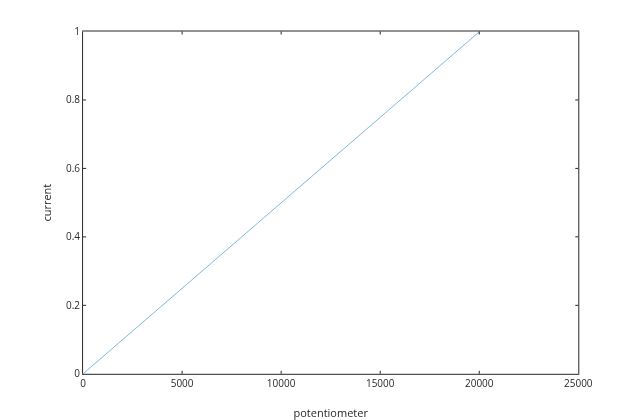

ans = 20020


In [22]:
graphics_toolkit plotly
displayformat plotly_interactive_legend true
displayformat include_comment true
syms Vm_s R_2 R_3 Rset_s;

Vcc=10 # [V]

# first we need to drop voltage to ~Vsense
Vsense = I_in*Rsense

Rpot_in=1e3
R1_in=1e6
Rset_in=Rpot_in*0.5
Vin=Vcc*(Rset_in/((Rpot_in-Rset_in+R1_in)+Rset_in)) # [V] input voltage for divider
#
# voltage divider
Rpot=20e3;

Io=linspace(0,I_in,15);
Vm=Io*Rsense;

Rset_s = solve((Rset_s / ((Rpot-Rset_s) + Rset_s))*Vin==Vm_s,Rset_s)

Rset=subs(Rset_s,{Vm_s},{Vm});

plot(double(Rset),Io)
xlabel("potentiometer")
ylabel("current")
ylim([0,max(Io)])
double(max(Rset))

# soft latching circuits
mosfet array IRF319PbF
![](<./img/soft_latching_switch.svg>)

https://www.falstad.com/s.php?s=kfboRS

# capacitor

## capacitor in series
$
C_{eq} = \left(\displaystyle\sum_{i=1}^n \frac{1}{C_i}\right)^{-1}
$


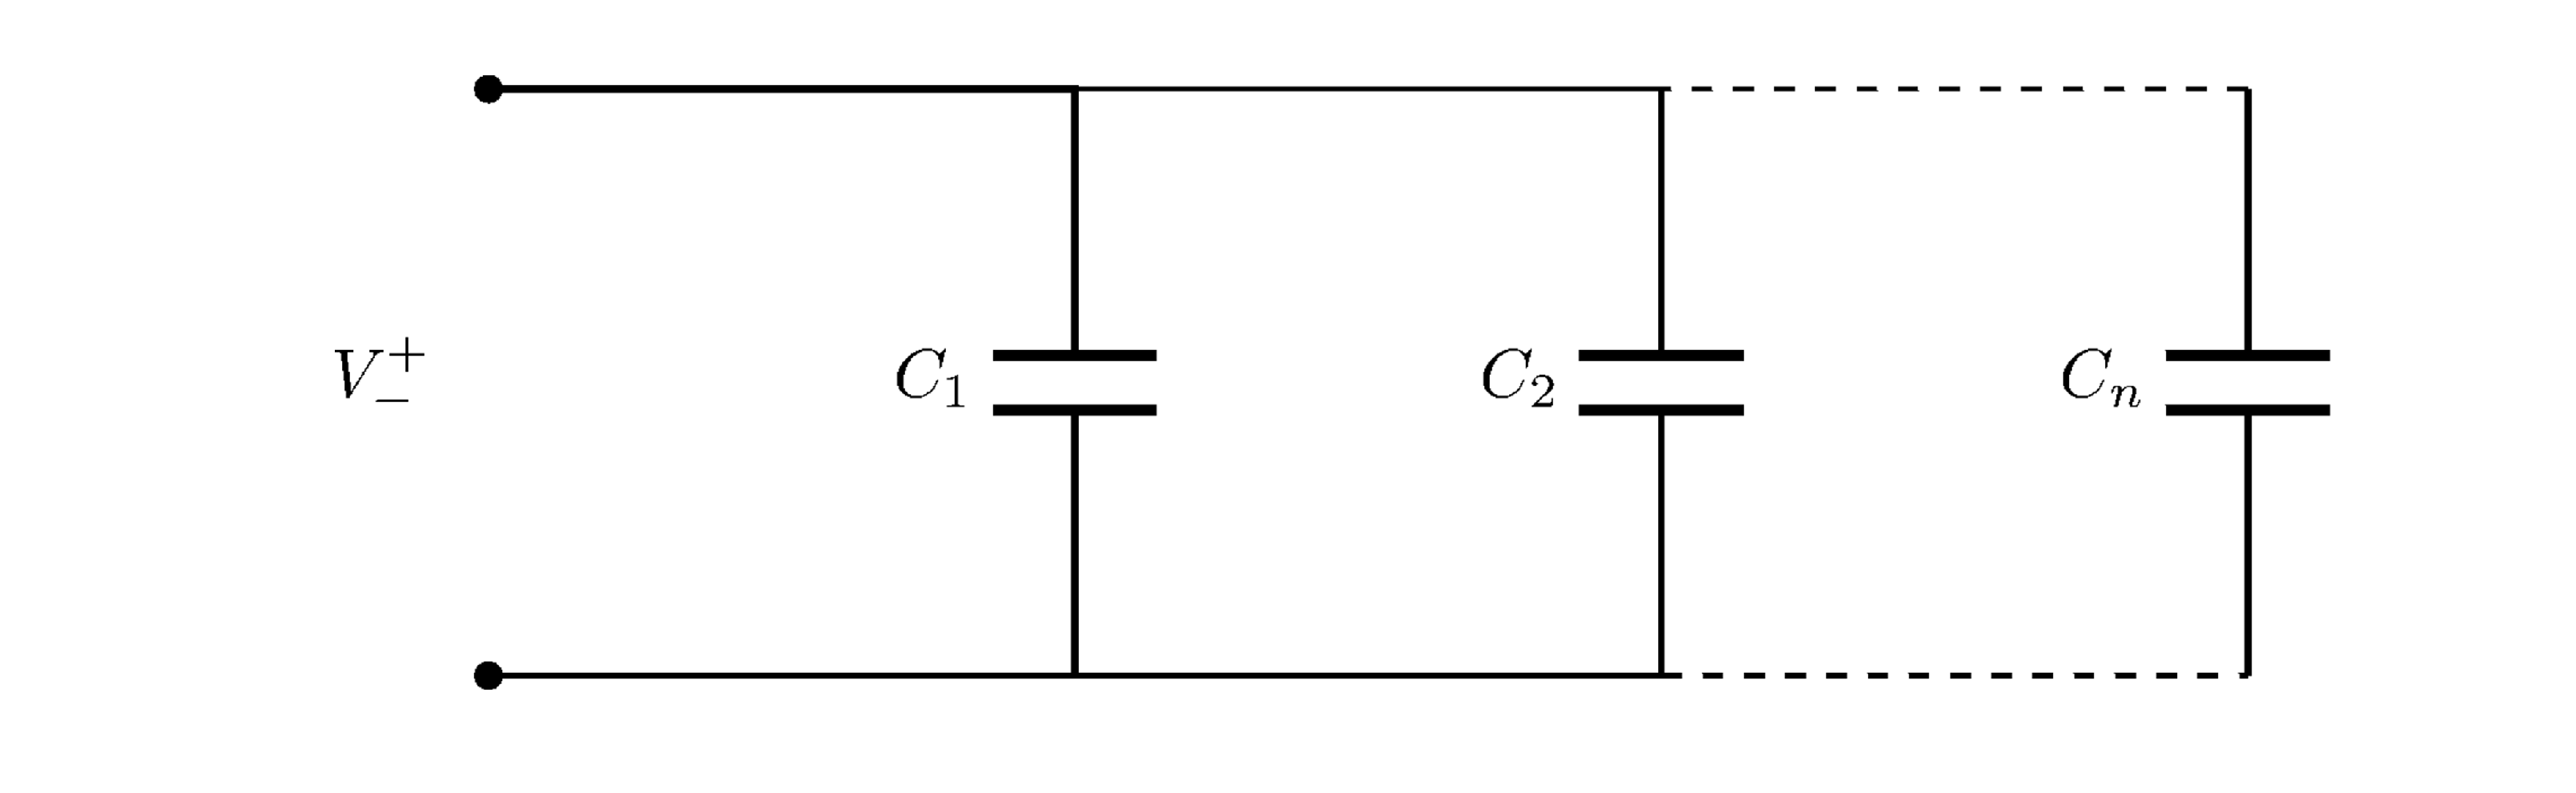

In [2]:
tikz({
    "\\draw[thick] (0,0) to[short,*-] ++(3,0) to[C=$C_1$] ++(0,3) to[short,-*] ++(-3,0);"
    "\\draw[thick] (3,0) -- ++(3,0) to[C=$C_2$] ++(0,3) -- ++(-3,0);"
    "\\draw[thick,dashed] (6,0) -- ++(3,0) to[open] ++(0,3) -- ++(-3,0);"
    "\\draw[thick]  (9,0) to[C=$C_n$] ++(0,3);"
    "\\draw (0,0) to[open=$V_-^+$] (0,3);"
},200)

In [55]:
function Ceq = Cseries(Cvec)
usage = {
"Cseries([1 2 3, ...])"
};
if nargin == 0
    disp("Usage:\n")
    disp(usage)
    error("Cseries: no input");
end

if !isvector(Cvec)
    error("Cseries: input must be a vector");
end

Ceq=0;
for i=1:length(Cvec)
    Ceq = Ceq + 1 / Cvec(i);
end
Ceq = 1/ Ceq;
end



## capacitor charging

$
I(t) = C \cdot \frac{dV(t)}{dt}
$

or

$
\frac{V_{in}-V(t)}{R} = C \cdot \frac{dV(t)}{dt}
$


In [4]:
displayformat include_comment true
pkg load symbolic
warning('off', 'all');

syms Vcap(t) Vm(t) C
% starting circuit
% charging cap through R1 and R2
R1=10e3;
R2=10e3;
R3=10e3 # aa
Vin=10;
C1=27e-9;
% keep C as symbol, other way the kernel strugle
% with typically very small values of C
% capacitor charging equation
cap = (Vin - Vcap(t))/(R1 + R2) == C * diff(Vcap, t);
Vcap(t,C) = dsolve(cap, Vcap(0)==0)
% current to cap
Icap(t,C) = (Vin - Vcap(t,C)) / (R1 + R2)
% mosfet voltage; Vg for p-mosfet and Vd for n-mosfet
Vm(t,C) = Vin - R1 * Icap(t,C)
% fully charged after
tfull=double(solve(Vcap(t,C1)==0.95 * Vin, t))*1e3 #[ms]


% starting circuit
% charging cap through R1 and R2


R3 = 10000 # aa


% keep C as symbol, other way the kernel strugle
% with typically very small values of C
% capacitor charging equation


% current to cap


% mosfet voltage; Vg for p-mosfet and Vd for n-mosfet


% fully charged after


tfull = 1.6177 #[ms]


In [1]:
syms Vcap_d(t)
% turning on
% discharging cap through R3
% cap must sustain Vth for time enough to turn on n-mosfet
tnon=12e-6

% capacitor discharging equation
cap_d = (Vcap_d(t) / R3) == -C * diff(Vcap_d, t);
Vcap_d(t) = dsolve(cap_d,Vcap_d(0)==Vin)
% voltge drop when n-mosfet turning on
double(Vcap_d(tnon)) # must be above Vth=1


Execution exception: 'syms' undefined near line 1, column 1

The 'syms' function belongs to the symbolic package from Octave Forge
which you have installed, but not loaded.  To load the package, type
‘pkg load symbolic’ from the Octave prompt.

In [ ]:
syms Vcap_c(t)
% turn off
% cap charging current through R3 
% cap must drain enough current do drop beloow Vth 
% for time enough to turn on n-mosfet
tnoff=13e-6
R3=10e3
#
% capacitor charging equation
cap_c = (Vin - Vcap_c(t)) / R3 == C * diff(Vcap_c, t);
Vcap_c(t) = dsolve(cap_c, Vcap_c(0)==0)

% voltge drop through R3 when n-mosfet turning off
double(Vcap_c(tnoff)) # must be below Vth=1V



In [ ]:
% n-mosfet power
Rdson = 0.046
In = Vin / (R1 + Rdson)
Pn = In^2 * Rdson

% p-mosfet max power
Pp = Vin * 100e-3 # max current from LDO

Vin * 5e-3 * 24

In [ ]:
% LED switch
If = 20e-3
Rled = Vin / If

In [ ]:
displayformat include_comment true
pkg load symbolic
warning('off', 'all');

syms Vcap(t) Vm(t)
% starting circuit
% charging cap through R1 and R2
R1=10e3;
R3=10e3;
Vin=10;
C=27e-6;
% capacitor charging equation
cap = (Vin - Vcap(t))/(R1 + R2) == C*1e-3 * diff(Vcap, t)
% Vcap(t) = dsolve(cap, Vcap(0)==0)
Vcap(t) = dsolve(cap, Vcap(0)==0)

$$
I=C* \frac{dV_{cap}}{dt}
$$

In [11]:
displayformat include_comment true
pkg load symbolic
warning('off', 'all');

syms Vcap(t) Vm(t) C
Vin=10
R1=10e3
C1=27e-9
tnoff=13e-6
cap = (Vin - Vcap(t)) / R1  == C  * diff(Vcap, t);
Vcap(t,C)=dsolve(cap,Vcap(0)==0)

double(Vcap(tnoff,C1))

Vin = 10


R1 = 10000


C1 = 2.7000e-08


tnoff = 1.3000e-05


ans = 0.4701


ERROR: received bad message: No such comm registered: a3fc237c-6518-4bbe-8115-f712b86787f9
Message type: comm_msg


In [ ]:
dsolve(cap, Vcap(0)==0)

In [ ]:
"displayformat include_comment true\npkg load symbolic\nwarning('off', 'all');\n\nsyms Vcap(t) Vm(t) C\n% starting circuit\n% charging cap through R1 and R2\nR1=10e3;\nR2=10e3;\nR3=10e3;\nVin=10;\nC1=27e-9;\n% capacitor charging equation\ncap = (Vin - Vcap(t))/(R1 + R2) == C * diff(Vcap, t);\nVcap(t,C) = dsolve(cap, Vcap(0)==0)\n% current to cap\nIcap(t,C) = (Vin - Vcap(t,C)) / (R1 + R2)\n% mosfet voltage; Vg for p-mosfet and Vd for n-mosfet\nVm(t,C) = Vin - R1 * Icap(t,C)\n% fully charged after\ntfull=double(solve(Vcap(t,C1)==0.95 * Vin, t))*1e3 #[ms]\nsyms Vcap_d(t)\n% turning on\n% discharging cap through R3\n% cap must sustain Vth for time enough to turn on n-mosfet\ntnon=12e-6\n\n% capacitor discharging equation\ncap_d = (Vcap_d(t) / R3) == -C * diff(Vcap_d, t);\nVcap_d(t) = dsolve(cap_d,Vcap_d(0)==Vin)\n% voltge drop when n-mosfet turning on\ndouble(Vcap_d(tnon)) # must be above Vth=1\nsyms Vcap_c(t)\n% turn off\n% cap charging current through R3 \n% cap must drain enough current do drop beloow Vth \n% for time enough to turn on n-mosfet\ntnoff=13e-6\nR3=10e3\n#\n% capacitor charging equation\ncap_c = (Vin - Vcap_c(t)) / R3 == C * diff(Vcap_c, t);\nVcap_c(t) = dsolve(cap_c, Vcap_c(0)==0)\n\n% voltge drop through R3 when n-mosfet turning off\ndouble(Vcap_c(tnoff)) # must be below Vth=1V\n\n% n-mosfet power\nRdson = 0.046\nIn = Vin / (R1 + Rdson)\nPn = In^2 * Rdson\n\n% p-mosfet max power\nPp = Vin * 100e-3 # max current from LDO\n\nVin * 5e-3 * 24% LED switch\nIf = 20e-3\nRled = Vin / Ifdisplayformat include_comment true\npkg load symbolic\nwarning('off', 'all');\n\nsyms Vcap(t) Vm(t)\n% starting circuit\n% charging cap through R1 and R2\nR1=10e3;\nR3=10e3;\nVin=10;\nC=27e-6;\n% capacitor charging equation\ncap = (Vin - Vcap(t))/(R1 + R2) == C*1e-3 * diff(Vcap, t)\n% Vcap(t) = dsolve(cap, Vcap(0)==0)\nVcap(t) = dsolve(cap, Vcap(0)==0)displayformat include_comment true\npkg load symbolic\nwarning('off', 'all');\n\nsyms Vcap(t) Vm(t) C\nVin=10\nR1=10e3\nC1=27e-9\ntnoff=13e-6\ncap = (Vin - Vcap(t)) / R1  == C  * diff(Vcap, t);\nVcap(t,C)=dsolve(cap,Vcap(0)==0)\n\ndouble(Vcap(tnoff,C1))dsolve(cap, Vcap(0)==0)\nplot"

ERROR: received bad message: No such comm registered: 26461f69-37a7-4c7e-921a-641da75d7b47
Message type: comm_msg
ERROR: received bad message: No such comm registered: 77fbf533-c225-4234-af9a-8c209a945452
Message type: comm_msg


In [ ]:
"displayformat include_comment true\npkg load symbolic\nwarning('off', 'all');\n\nsyms Vcap(t) Vm(t) C\n% starting circuit\n% charging cap through R1 and R2\nR1=10e3;\nR2=10e3;\nR3=10e3;\nVin=10;\nC1=27e-9;\n% capacitor charging equation\ncap = (Vin - Vcap(t))/(R1 + R2) == C * diff(Vcap, t);\nVcap(t,C) = dsolve(cap, Vcap(0)==0)\n% current to cap\nIcap(t,C) = (Vin - Vcap(t,C)) / (R1 + R2)\n% mosfet voltage; Vg for p-mosfet and Vd for n-mosfet\nVm(t,C) = Vin - R1 * Icap(t,C)\n% fully charged after\ntfull=double(solve(Vcap(t,C1)==0.95 * Vin, t))*1e3 #[ms]\nsyms Vcap_d(t)\n% turning on\n% discharging cap through R3\n% cap must sustain Vth for time enough to turn on n-mosfet\ntnon=12e-6\n\n% capacitor discharging equation\ncap_d = (Vcap_d(t) / R3) == -C * diff(Vcap_d, t);\nVcap_d(t) = dsolve(cap_d,Vcap_d(0)==Vin)\n% voltge drop when n-mosfet turning on\ndouble(Vcap_d(tnon)) # must be above Vth=1\nsyms Vcap_c(t)\n% turn off\n% cap charging current through R3 \n% cap must drain enough current do drop beloow Vth \n% for time enough to turn on n-mosfet\ntnoff=13e-6\nR3=10e3\n#\n% capacitor charging equation\ncap_c = (Vin - Vcap_c(t)) / R3 == C * diff(Vcap_c, t);\nVcap_c(t) = dsolve(cap_c, Vcap_c(0)==0)\n\n% voltge drop through R3 when n-mosfet turning off\ndouble(Vcap_c(tnoff)) # must be below Vth=1V\n\n% n-mosfet power\nRdson = 0.046\nIn = Vin / (R1 + Rdson)\nPn = In^2 * Rdson\n\n% p-mosfet max power\nPp = Vin * 100e-3 # max current from LDO\n\nVin * 5e-3 * 24% LED switch\nIf = 20e-3\nRled = Vin / Ifdisplayformat include_comment true\npkg load symbolic\nwarning('off', 'all');\n\nsyms Vcap(t) Vm(t)\n% starting circuit\n% charging cap through R1 and R2\nR1=10e3;\nR3=10e3;\nVin=10;\nC=27e-6;\n% capacitor charging equation\ncap = (Vin - Vcap(t))/(R1 + R2) == C*1e-3 * diff(Vcap, t)\n% Vcap(t) = dsolve(cap, Vcap(0)==0)\nVcap(t) = dsolve(cap, Vcap(0)==0)displayformat include_comment true\npkg load symbolic\nwarning('off', 'all');\n\nsyms Vcap(t) Vm(t) C\nVin=10\nR1=10e3\nC1=27e-9\ntnoff=13e-6\ncap = (Vin - Vcap(t)) / R1  == C  * diff(Vcap, t);\nVcap(t,C)=dsolve(cap,Vcap(0)==0)\n\ndouble(Vcap(tnoff,C1))dsolve(cap, Vcap(0)==0)\nplot"

## BASIC ASSUMPTIONS
It is impossible? to have one MOSFET going full up to 3.5A and in the same time stay precise in low range of curents.\n- modular approach: 4 modules\n    - three IXTP4N65X2 MOSFETS for 0.4A to 1A\n    - one precise STF2N95K5 for 0 to 0.5A\n- maximum total $V_{in}$=24V and $I_{in}$=3.5A\n- minimum $V_{in}$=1V and $I_{in}$=0.10mA\n- $V_{ref}$ will be set with potentiometer, each mosfet separately\n- can be one common display\n- interface for current sensing on low side\n- device power from external supply: main 220V AC

In [24]:
function tikz(circuit,res)
  % requires latex to be installed in system
  % texlive in opensuse takes 1.4GB!!!
  % use tinytex to install only what needed (51MB):
  % - standalone
  % - pgf
  % - circuitikz
  % - pdfcrop
  
  Usage={
    "tikz(\"\\draw (0,0) to[R] (2,0);\",res) // string",
    "tikz({\"line1\", \"line2\", ...},res)   // cell array"
    "adjust `res` if strange rendering or kernel crash"
  };

  if nargin == 0
    disp("Usage:\n")
    disp(Usage)
    error("tikz: no input");
  end
  if nargin==1
      res=100;
  end

  % Accept string OR cell array
  if iscell(circuit)
    body = strjoin(circuit, "\n");
  else
    body = circuit;
  end

  tex = [
    "\\documentclass[tikz,border=3pt]{standalone}\n" ...
    "\\usepackage{circuitikz}\n" ...
    "\\begin{document}\n" ...
    "\\begin{circuitikz}\n" ...
    body "\n" ...
    "\\end{circuitikz}\n" ...
    "\\end{document}\n"
  ];

  tmp = tempname();
  texfile = [tmp ".tex"];
  pdffile = [tmp ".pdf"];
  auxfile = [tmp ".aux"];
  logfile = [tmp ".log"];
  cropdfile = [tmp "_crop.pdf"];
  pngbase = [tmp];
  pngfile = [pngbase "-1.png"];
  imgfile = [pngbase "_resize.png"];
  
  fid = fopen(texfile, "w");
  fwrite(fid, tex);
  fclose(fid);

  % Compile circuitikz to pdf
  system(sprintf(
    "pdflatex -interaction=nonstopmode -halt-on-error -output-directory %s %s > /dev/null",
    fileparts(texfile), texfile
  ));

  % Auto-crop PDF (tight bounding box around circuit)
  system(sprintf(
    "pdfcrop --hires %s %s > /dev/null", 
    pdffile, cropdfile
  ));


  % Convert PDF → PNG
  system(sprintf(
    "pdftoppm -png -r 400 -mono %s %s > /dev/null", 
    cropdfile, pngbase
  ));

  % resize
   system(sprintf(
       "magick %s -resize %d%%  -interpolate Nearest %s > /dev/null", 
       pngfile, res,imgfile
    ));

  

  if exist(imgfile, "file")
     img = imread(imgfile);
     % pdftoppm -mono is producing PNG with pixels in range [0,1]
     % imshow() is expecting [0,255]
     % or double, but double takes more memory
     % img = 255 * uint8(img);
     figure('Position', [0 0 size(img, 2) size(img,1)]);
     imshow(img);
     % colormap(gray(256));
     axis image off;
  else
     error("tikz: rendering failed");
  end
  delete(texfile);
  delete(pdffile);
  delete(cropdfile);
  delete(pngfile);
  delete(imgfile);
  delete(auxfile);
  delete(logfile);
end



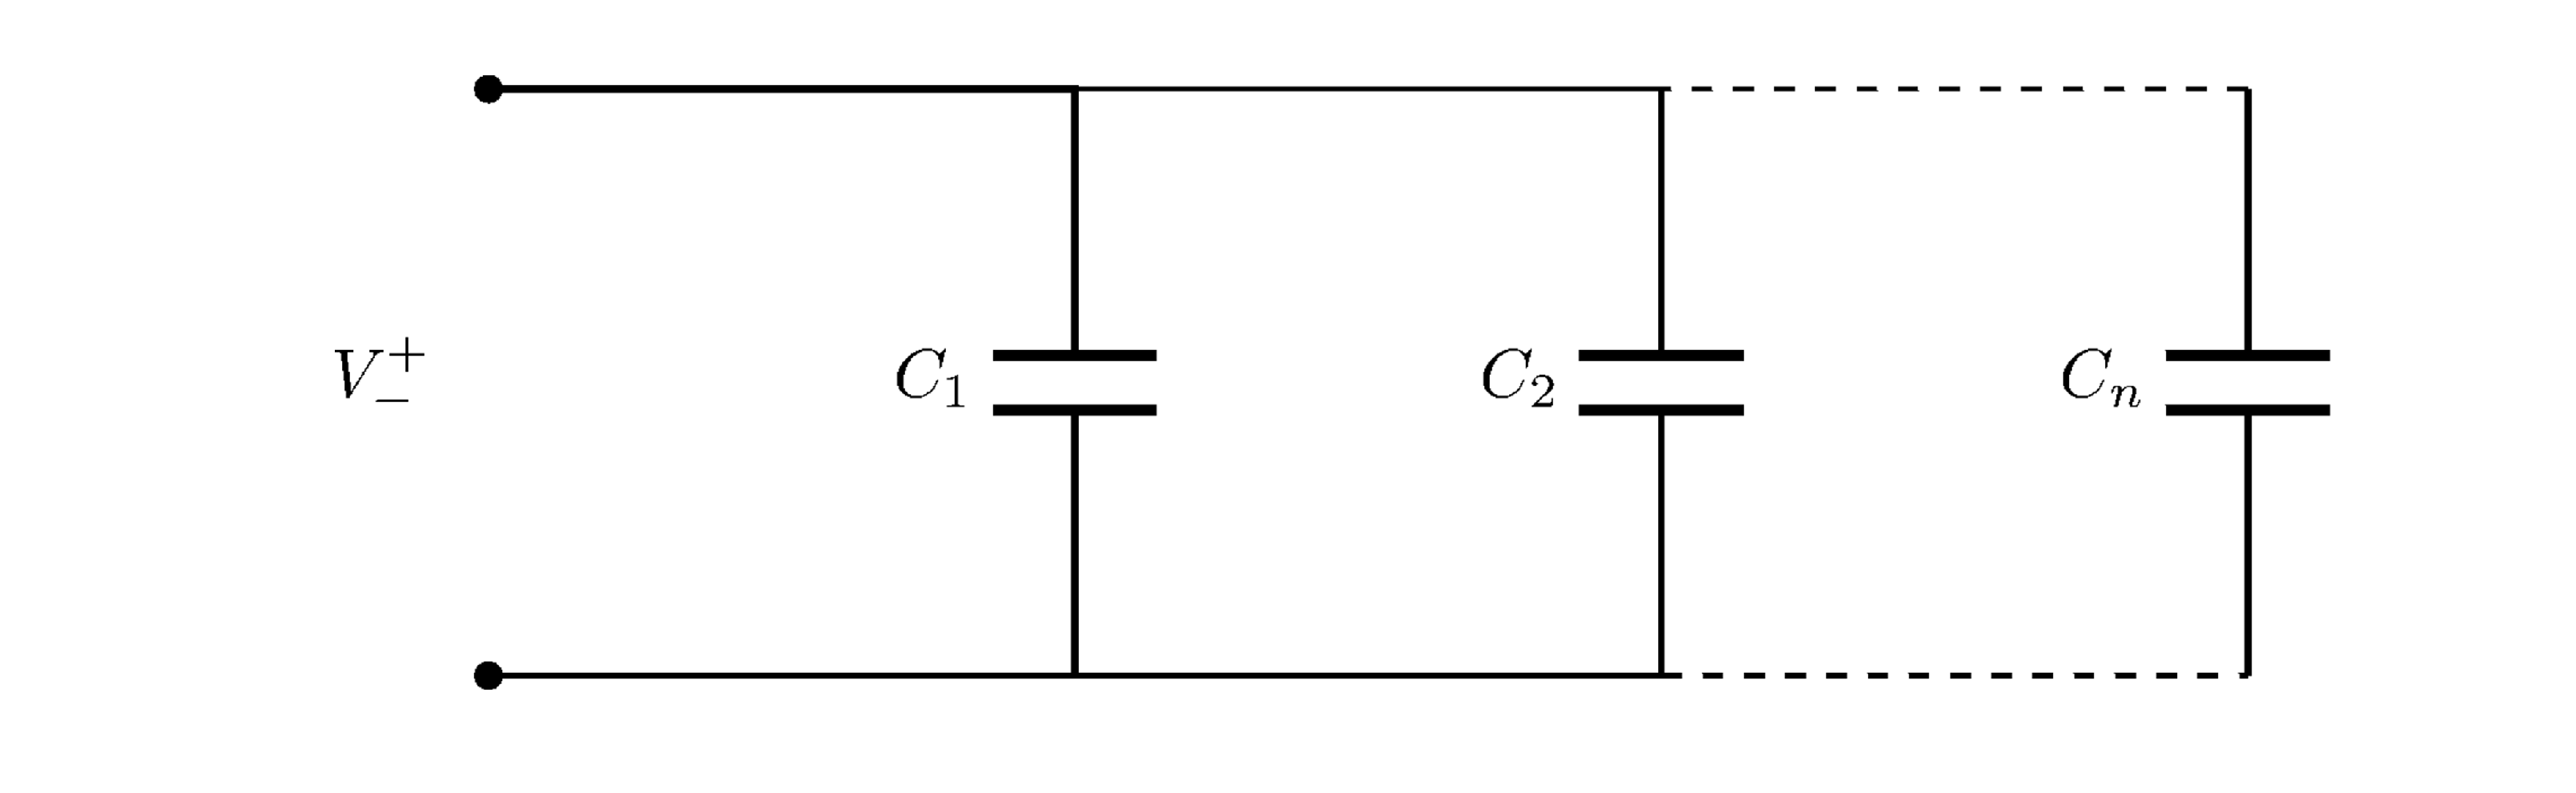

In [25]:
tikz({
    "\\draw[thick] (0,0) to[short,*-] ++(3,0) to[C=$C_1$] ++(0,3) to[short,-*] ++(-3,0);"
    "\\draw[thick] (3,0) -- ++(3,0) to[C=$C_2$] ++(0,3) -- ++(-3,0);"
    "\\draw[thick,dashed] (6,0) -- ++(3,0) to[open] ++(0,3) -- ++(-3,0);"
    "\\draw[thick]  (9,0) to[C=$C_n$] ++(0,3);"
    "\\draw (0,0) to[open=$V_-^+$] (0,3);"
},200)

In [26]:
tikz()

Usage:

{
  [1,1] = tikz("\draw (0,0) to[R] (2,0);",res) // string
  [2,1] = tikz({"line1", "line2", ...},res)   // cell array
  [3,1] = adjust `res` if strange rendering or kernel crash
}


Execution exception: tikz: no input